# 🔍 MayaLens — Integrated Deepfake Detection powered by Explainable AI


###
| Source | Implemented in |
|---|---|
| Pipeline: *1 Media Ingestion → 2 Preprocessing (MTCNN · Landmark Alignment · Multi-scale Crop) → 3 Core Models → 4 XAI → 5 Report* | Cells 4-10 (ingest + preprocess), 11-16 (model), 19-21 (XAI + report) |
| **EfficientNet (Artifact Analysis)** | Spatial stream, `EfficientNetB4` (ImageNet init) on the *tight* face crop |
| **Vision Transformer (Contextual Analysis)** | ViT stream on the *context* (wide, multi-scale) crop |
| Report §5: **Frequency stream (FFT/DCT → ResNet-18)** | `FrequencyTransform` layer + ResNet-18 on the spectral map |
| Report §5: **Feature Fusion & Classification Head, BCE + label smoothing ε = 0.1** | `fusion_concat → final_pred` |
| **Grad-CAM / Grad-CAM++ · LIME · Saliency (key-frame ID)** | `XAIEngine` |
| UML class diagram (`MediaItem, FaceDetector, SpatialStream, FrequencyStream, MayaLensClassifier, PredictionResult, XAIEngine, ReportGenerator`) | Same class / method names in cell 17-20 |
| Sequence diagram (submit → ingest → preprocess → predict → explain → report → deliver) | `MayaLensController.submit_media()` |



> **Runtime → Change runtime type → GPU (T4 or better).**  
> Recommended order: run cells top-to-bottom.

## 1 · Install dependencies

In [1]:
!pip install -q tf_keras lime kaggle reportlab scikit-image seaborn
!pip install -q facenet-pytorch --no-deps      # MTCNN (PyTorch) – used only for face detection + landmarks
print("Done. If pip upgraded TensorFlow, restart the runtime once (Runtime > Restart session) and continue from the next cell.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 7.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 64.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 28.7 MB/s eta 0:00:00
Done. If pip upgraded TensorFlow, restart the runtime once (Runtime > Restart session) and continue from the next cell.


## 2 · Imports, Keras-2 mode, Drive, GPU

In [2]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"          # MUST be set before TensorFlow is imported (reliable .h5 saving)

import sys, json, math, random, shutil, time, warnings, hashlib, re, zipfile
from pathlib import Path
from dataclasses import dataclass, field
from typing import List, Dict, Tuple, Optional

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import tensorflow as tf
import tf_keras as keras
from tf_keras import layers

warnings.filterwarnings("ignore")
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
assert keras.__version__.startswith("2"), "Keras 3 detected -> restart runtime after cell 1 so TF_USE_LEGACY_KERAS takes effect."
print("GPUs:", tf.config.list_physical_devices("GPU"))
assert layers.Conv2D.__module__.startswith("tf_keras"), layers.Conv2D.__module__
assert keras.applications.EfficientNetB4.__module__.startswith("tf_keras")

from google.colab import drive
drive.mount("/content/drive")

TensorFlow: 2.21.0 | Keras: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive


## 3 · Configuration & dataset registry
Datasets follow the report (§3.2): **FaceForensics++** (train/val/test), **Celeb-DF v2** (zero-shot generalisation), **DFDC** (robustness, optional), **CIFAKE** (synthetic-image branch).

* `role='train'` → split 80/10/10 **by video/identity group** (no frame leakage).  `role='test'` → never used for training.
* `local_dir` → point to a copy on Google Drive to skip the Kaggle download.
* Reduce `max_per_class` / `FRAMES_PER_VIDEO` to fit your Colab time budget.
* ⚠️ Kaggle slugs change over time — verify each one on kaggle.com. FF++ is large; `subset_download=True` fetches only the selected files.

In [3]:
class CFG:
    SEED            = 42
    IMG_SIZE        = 224             # EfficientNet-B4 native is 380; 224 keeps Colab memory/time sane (must be divisible by ViT patch)
    BATCH_SIZE      = 32
    WORK_DIR        = Path("/content/mayalens")
    DRIVE_DIR       = Path("/content/drive/MyDrive/MayaLens")
    RAW_DIR         = WORK_DIR / "raw"
    FACE_DIR        = WORK_DIR / "faces"
    JSONL           = WORK_DIR / "preprocess_log.jsonl"
    MANIFEST        = WORK_DIR / "manifest.csv"
    # --- preprocessing (Pipeline stage 2)
    FRAMES_PER_VIDEO = 10
    MTCNN_MIN_PROB   = 0.90
    DETECT_MAX_SIDE  = 640            # frames are down-scaled to this for detection only
    TIGHT_SCALE      = 1.15           # multi-scale crop #1 : face + small margin  -> EfficientNet + Frequency stream
    CONTEXT_SCALE    = 1.70           # multi-scale crop #2 : head/neck/background -> Vision Transformer
    JPEG_QUALITY     = 95
    IMAGE_FALLBACK_FULL = True        # image datasets w/o detectable face (e.g. 32x32 CIFAKE): use the whole image
    # --- model / training
    LABEL_SMOOTHING  = 0.1            # ε from report §5.2
    VIT_DIM, VIT_DEPTH, VIT_HEADS, VIT_PATCH = 192, 6, 3, 16
    FEAT_DIM         = 256
    DROPOUT          = 0.4
    EPOCHS_HEAD      = 6              # phase-1: backbone frozen
    EPOCHS_FINETUNE  = 12             # phase-2: top of EfficientNet unfrozen
    UNFREEZE_LAST    = 120
    LR_HEAD, LR_FINE = 1e-3, 1e-4

for d in (CFG.WORK_DIR, CFG.RAW_DIR, CFG.FACE_DIR, CFG.DRIVE_DIR):
    d.mkdir(parents=True, exist_ok=True)
random.seed(CFG.SEED); np.random.seed(CFG.SEED); tf.random.set_seed(CFG.SEED)
assert CFG.IMG_SIZE % CFG.VIT_PATCH == 0

DATASETS = {
    "ffpp":    dict(enabled=True,  kind="video", role="train", slug="xdxd003/ff-c23",
                    local_dir=None, max_per_class=450, subset_download=True,  label_mode="path"),
    "celebdf": dict(enabled=True,  kind="video", role="test",  slug="reubensuju/celeb-df-v2",
                    local_dir=None, max_per_class=200, subset_download=True,  label_mode="path"),

    "cifake":  dict(enabled=True,  kind="image", role="train", slug="birdy654/cifake-real-and-ai-generated-synthetic-images",
                    local_dir=None, max_per_class=6000, subset_download=False, label_mode="path"),
}
print({k: v["enabled"] for k, v in DATASETS.items()})


{'ffpp': True, 'celebdf': True, 'cifake': True}


Optional: DFDC #"dfdc":    dict(enabled=True, kind="video", role="test",  slug="pranay22077/dfdc-10",
                   local_dir=None, max_per_class=100, subset_download=False, label_mode="metadata")

## 4 · Data ingestion (Stage 1) — Kaggle download

In [4]:
def setup_kaggle():
    """Use Colab Secrets (KAGGLE_USERNAME / KAGGLE_KEY) or fall back to uploading kaggle.json."""
    try:
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        print("Kaggle credentials loaded from Colab Secrets.")
        return
    except Exception:
        pass
    kj = Path.home() / ".kaggle" / "kaggle.json"
    if not kj.exists():
        from google.colab import files
        print("Upload your kaggle.json (Kaggle > Settings > API > Create New Token)")
        up = files.upload()
        kj.parent.mkdir(exist_ok=True)
        shutil.move(list(up.keys())[0], kj)
        os.chmod(kj, 0o600)

VIDEO_EXT = {".mp4", ".avi", ".mov", ".mkv", ".webm"}
IMG_EXT   = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
FAKE_KEYS = ["deepfakedetection", "deepfakes", "face2face", "faceswap", "neuraltextures", "faceshifter",
             "manipulated", "synthesis", "fake", "forged", "generated"]
REAL_KEYS = ["original", "real", "youtube", "pristine", "authentic"]

def infer_label(dir_parts):
    """Label from the *relative directory names* (FF++: original vs Deepfakes/Face2Face/..., Celeb-DF: *-real vs Celeb-synthesis, CIFAKE: REAL/FAKE)."""
    joined = "/".join(p.lower() for p in dir_parts)
    for k in FAKE_KEYS:
        if k in joined: return 1, k
    for k in REAL_KEYS:
        if k in joined: return 0, "real"
    return None, None

def _list_kaggle_files(api, slug):
    names, token = [], None
    while True:
        try:    res = api.dataset_list_files(slug, page_token=token, page_size=200)
        except TypeError: res = api.dataset_list_files(slug); # Older kaggle.api does not have 'page_token' argument
        fs = getattr(res, "files", None) or []
        names += [getattr(f, "name", None) or str(f) for f in fs]
        token = getattr(res, "next_page_token", None) or getattr(res, "nextPageToken", None)
        if not token: break
    return names

def _subset_download(api, ds, target):
    """Download only max_per_class real + max_per_class fake video files (fakes stratified over manipulation types)."""
    names = [n for n in _list_kaggle_files(api, ds["slug"]) if Path(n).suffix.lower() in VIDEO_EXT]
    rows = []
    for n in names:
        lab, manip = infer_label(Path(n).parts[:-1])
        if lab is not None: rows.append(dict(name=n, label=lab, manip=manip))
    df = pd.DataFrame(rows)
    if df.empty: raise RuntimeError("Could not infer labels from the Kaggle file listing.")
    sel = sample_balanced(df, ds["max_per_class"])
    print(f"Subset download: {len(sel)} files ({(sel.label==0).sum()} real / {(sel.label==1).sum()} fake)")
    for n in tqdm(sel.name):
        dest = target / Path(n).parent
        dest.mkdir(parents=True, exist_ok=True)
        api.dataset_download_file(ds["slug"], n, path=str(dest), quiet=True)
        for z in dest.glob("*.zip"):
            with zipfile.ZipFile(z) as zf: zf.extractall(dest)
            z.unlink()
    return True

def sample_balanced(df, n, seed=CFG.SEED):
    """n real + n fake; fakes are stratified across manipulation types."""
    real = df[df.label == 0]; fake = df[df.label == 1]
    real = real.sample(min(n, len(real)), random_state=seed)
    if len(fake):
        per = math.ceil(n / max(1, fake.manip.nunique()))
        fake = pd.concat([g.sample(min(len(g), per), random_state=seed) for _, g in fake.groupby("manip")])
        fake = fake.sample(min(n, len(fake)), random_state=seed)
    return pd.concat([real, fake])

def download_dataset(name, ds):
    if ds.get("local_dir"): return Path(ds["local_dir"])
    target = CFG.RAW_DIR / name
    if target.exists() and any(target.rglob("*.*")):
        print(f"[{name}] already present -> {target}"); return target
    assert ds["slug"], f"[{name}] no Kaggle slug / local_dir set."
    target.mkdir(parents=True, exist_ok=True)
    setup_kaggle()
    from kaggle.api.kaggle_api_extended import KaggleApi
    api = KaggleApi(); api.authenticate()
    if ds.get("subset_download") and ds["kind"] == "video":
        try:
            _subset_download(api, ds, target); return target
        except Exception as e:
            print(f"[{name}] subset download failed ({e}); falling back to FULL download (check free disk space!)")
    api.dataset_download_files(ds["slug"], path=str(target), unzip=True, quiet=False)
    return target

In [5]:
DATA_ROOTS = {}
for name, ds in DATASETS.items():
    if ds["enabled"]:
        DATA_ROOTS[name] = download_dataset(name, ds)
print(DATA_ROOTS)

Kaggle credentials loaded from Colab Secrets.
Subset download: 900 files (450 real / 450 fake)


  0%|          | 0/900 [00:00<?, ?it/s]

Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Dataset URL: https://www.kaggle.com/data

  0%|          | 0/400 [00:00<?, ?it/s]

Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
Dataset URL: https://www.kaggle.com/datasets/reu

100%|██████████| 105M/105M [00:00<00:00, 186MB/s] 



{'ffpp': PosixPath('/content/mayalens/raw/ffpp'), 'celebdf': PosixPath('/content/mayalens/raw/celebdf'), 'cifake': PosixPath('/content/mayalens/raw/cifake')}


## 5 · Build the media index (labels, manipulation type, group ids)
Labels are inferred from folder names (FF++: `original` = real; `Deepfakes / Face2Face / FaceSwap / NeuralTextures / FaceShifter / DeepFakeDetection` = fake; Celeb-DF: `Celeb-real`, `YouTube-real` vs `Celeb-synthesis`; CIFAKE: `REAL` / `FAKE`; DFDC: `metadata.json`).  
**Check the printed counts** — if a class is empty, adjust `FAKE_KEYS / REAL_KEYS` above.  
Group id = identity/video root (e.g. FF++ `123_456.mp4` → group `123`) so all frames of one identity land in the same split.

In [6]:
def load_dfdc_metadata(root):
    meta = {}
    for mp in Path(root).rglob("metadata.json"):
        with open(mp) as f: d = json.load(f)
        for fn, v in d.items():
            if isinstance(v, dict) and "label" in v: meta[fn] = v["label"]
    return meta

def build_index(name, ds, root):
    root = Path(root); rows = []
    exts = VIDEO_EXT if ds["kind"] == "video" else IMG_EXT
    meta = load_dfdc_metadata(root) if ds["label_mode"] == "metadata" else {}
    for p in tqdm(list(root.rglob("*")), desc=f"indexing {name}", leave=False):
        if not p.is_file() or p.suffix.lower() not in exts: continue
        rel = p.relative_to(root)
        if ds["label_mode"] == "metadata":
            lab = meta.get(p.name)
            if lab is None: continue
            label, manip = (1, "dfdc_fake") if str(lab).upper() == "FAKE" else (0, "real")
        else:
            label, manip = infer_label(rel.parts[:-1])
            if label is None: continue
        grp = str(rel) if ds["kind"] == "image" else re.split(r"[_\-. ]", p.stem)[0]
        rows.append(dict(dataset=name, src_path=str(p), kind=ds["kind"], label=label, manip=manip,
                         group=f"{name}:{grp}", uid=hashlib.md5(str(p).encode()).hexdigest()[:12]))
    return pd.DataFrame(rows)

parts = []
for name, root in DATA_ROOTS.items():
    full = build_index(name, DATASETS[name], root)
    if full.empty:
        print(f"⚠️  [{name}] no labelled media found under {root}. Inspect the folder layout and adjust FAKE_KEYS/REAL_KEYS."); continue
    print(f"[{name}] found real={int((full.label==0).sum())} fake={int((full.label==1).sum())} | manip types: {full.manip.value_counts().to_dict()}")
    parts.append(sample_balanced(full, DATASETS[name]["max_per_class"]))
if not parts:
    raise RuntimeError("No labelled media found in enabled datasets. Check DATASETS paths, folder labels, and FAKE_KEYS/REAL_KEYS.")
index_df = pd.concat(parts, ignore_index=True)
print("\nSelected for preprocessing:"); print(index_df.groupby(["dataset", "label"]).size().unstack(fill_value=0))

indexing ffpp:   0%|          | 0/908 [00:00<?, ?it/s]

[ffpp] found real=450 fake=450 | manip types: {'real': 450, 'faceswap': 75, 'deepfakes': 75, 'deepfakedetection': 75, 'neuraltextures': 75, 'faceshifter': 75, 'face2face': 75}


indexing celebdf:   0%|          | 0/403 [00:00<?, ?it/s]

[celebdf] found real=200 fake=200 | manip types: {'synthesis': 200, 'real': 200}


indexing cifake:   0%|          | 0/120006 [00:00<?, ?it/s]

[cifake] found real=60000 fake=60000 | manip types: {'real': 60000, 'fake': 60000}

Selected for preprocessing:
label       0     1
dataset            
celebdf   200   200
cifake   6000  6000
ffpp      450   450


## 6 · Preprocessing (Stage 2) — `MediaItem`, `FaceDetector` (MTCNN), landmark alignment, multi-scale cropping
* **`MediaItem.extractFrames`** – evenly-spaced frames (skips first/last 1/(n+1) to avoid black intro frames).
* **`FaceDetector.detectFaces`** – MTCNN boxes + 5 landmarks (largest face is analysed).
* **`FaceDetector.alignFace`** – rotates so the eye-line is horizontal (*Landmark Alignment*), then cuts a square at a given scale (*Multi-scale Cropping*): **tight** (1.15×) and **context** (1.70×).

In [7]:
@dataclass
class BoundingBox:
    x1: float; y1: float; x2: float; y2: float
    prob: float = 1.0
    landmarks: Optional[np.ndarray] = None       # (5,2): l-eye, r-eye, nose, l-mouth, r-mouth
    @property
    def w(self): return self.x2 - self.x1
    @property
    def h(self): return self.y2 - self.y1
    @property
    def cx(self): return (self.x1 + self.x2) / 2
    @property
    def cy(self): return (self.y1 + self.y2) / 2

@dataclass
class MediaItem:
    fileId: str
    filePath: str
    mediaType: str                      # 'image' | 'video'
    frameCount: int = 0

    @staticmethod
    def from_path(path):
        p = Path(path); ext = p.suffix.lower()
        mtype = "video" if ext in VIDEO_EXT else "image" if ext in IMG_EXT else None
        if mtype is None: raise ValueError(f"Unsupported media type: {ext}")
        n = 1
        if mtype == "video":
            cap = cv2.VideoCapture(str(p)); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); cap.release()
        return MediaItem(hashlib.md5(str(p).encode()).hexdigest()[:12], str(p), mtype, n)

    def extractFrames(self, n=CFG.FRAMES_PER_VIDEO) -> List[Tuple[int, np.ndarray]]:
        if self.mediaType == "image":
            img = cv2.imread(self.filePath, cv2.IMREAD_COLOR)
            return [] if img is None else [(0, cv2.cvtColor(img, cv2.COLOR_BGR2RGB))]
        cap = cv2.VideoCapture(self.filePath)
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total <= 0: cap.release(); return []
        idxs = np.unique(np.linspace(0, total - 1, n + 2)[1:-1].astype(int)) if total > n + 2 else np.arange(total)
        out = []
        for i in idxs:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
            ok, fr = cap.read()
            if ok: out.append((int(i), cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)))
        cap.release()
        return out

class FaceDetector:
    def __init__(self, modelName="MTCNN", confidenceThreshold=CFG.MTCNN_MIN_PROB):
        import torch
        from facenet_pytorch import MTCNN
        self.modelName, self.confidenceThreshold = modelName, confidenceThreshold
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        self.mtcnn = MTCNN(keep_all=True, device=dev, post_process=False, min_face_size=40, thresholds=[0.6, 0.7, 0.7])

    def detectFaces(self, frame_rgb) -> List[BoundingBox]:
        h, w = frame_rgb.shape[:2]
        s = min(1.0, CFG.DETECT_MAX_SIDE / max(h, w))
        small = cv2.resize(frame_rgb, (int(w * s), int(h * s))) if s < 1 else frame_rgb
        boxes, probs, lms = self.mtcnn.detect(small, landmarks=True)
        if boxes is None: return []
        out = [BoundingBox(*(b / s), float(p), l / s) for b, p, l in zip(boxes, probs, lms)
               if p is not None and p >= self.confidenceThreshold]
        return sorted(out, key=lambda b: -(b.w * b.h))

    def alignFace(self, frame_rgb, box: BoundingBox, scale=CFG.TIGHT_SCALE, out_size=CFG.IMG_SIZE) -> np.ndarray:
        h, w = frame_rgb.shape[:2]
        le, re_ = box.landmarks[0], box.landmarks[1]
        angle = math.degrees(math.atan2(re_[1] - le[1], re_[0] - le[0]))        # eye-line tilt
        M = cv2.getRotationMatrix2D((box.cx, box.cy), angle, 1.0)
        rot = cv2.warpAffine(frame_rgb, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
        side = max(int(round(max(box.w, box.h) * scale)), 8)
        patch = cv2.getRectSubPix(rot, (side, side), (box.cx, box.cy))
        interp = cv2.INTER_AREA if side > out_size else cv2.INTER_CUBIC
        return cv2.resize(patch, (out_size, out_size), interpolation=interp)

detector = FaceDetector()
print("MTCNN ready.")

MTCNN ready.


### 6b · Quick visual check of the preprocessing on one sample

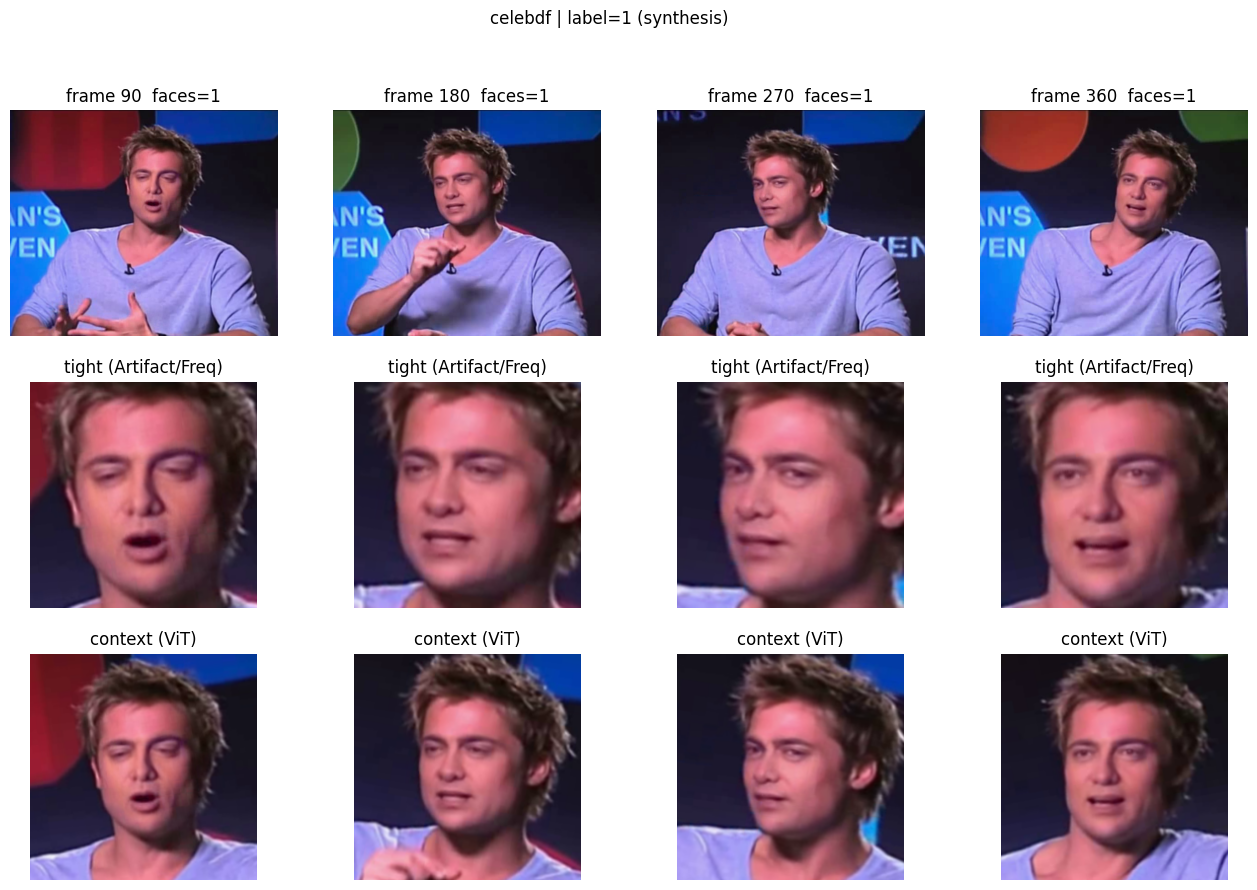

In [8]:
row = index_df[(index_df.kind == "video")].sample(1, random_state=1).iloc[0] if (index_df.kind == "video").any() else index_df.iloc[0]
item = MediaItem.from_path(row.src_path)
frames = item.extractFrames(4)
fig, ax = plt.subplots(3, len(frames), figsize=(4 * len(frames), 10))
ax = np.atleast_2d(ax).reshape(3, -1)
for j, (fi, fr) in enumerate(frames):
    boxes = detector.detectFaces(fr)
    ax[0, j].imshow(fr); ax[0, j].set_title(f"frame {fi}  faces={len(boxes)}"); ax[0, j].axis("off")
    if boxes:
        b = boxes[0]
        ax[1, j].imshow(detector.alignFace(fr, b, CFG.TIGHT_SCALE));   ax[1, j].set_title("tight (Artifact/Freq)")
        ax[2, j].imshow(detector.alignFace(fr, b, CFG.CONTEXT_SCALE)); ax[2, j].set_title("context (ViT)")
    for a in ax[:, j]: a.axis("off")
plt.suptitle(f"{row.dataset} | label={row.label} ({row.manip})"); plt.show()

## 7 · Run preprocessing over the whole index (resumable)
Each frame → aligned **tight** + **context** JPEG crops on local disk. Progress is appended to a JSONL log, so if Colab disconnects you can simply re-run this cell.

In [9]:
def preprocess_item(row) -> List[dict]:
    item = MediaItem.from_path(row.src_path)
    n = CFG.FRAMES_PER_VIDEO if item.mediaType == "video" else 1
    out_dir = CFG.FACE_DIR / row.dataset / str(row.label); out_dir.mkdir(parents=True, exist_ok=True)
    recs = []
    for fidx, fr in item.extractFrames(n):
        found, prob = False, 0.0
        boxes = detector.detectFaces(fr) if min(fr.shape[:2]) >= 64 else []
        if boxes:
            b = boxes[0]; found, prob = True, b.prob
            tight = detector.alignFace(fr, b, CFG.TIGHT_SCALE)
            ctx   = detector.alignFace(fr, b, CFG.CONTEXT_SCALE)
        elif item.mediaType == "image" and CFG.IMAGE_FALLBACK_FULL:
            tight = ctx = cv2.resize(fr, (CFG.IMG_SIZE, CFG.IMG_SIZE), interpolation=cv2.INTER_CUBIC)
        else:
            continue
        tp = out_dir / f"{row.uid}_{fidx:05d}_t.jpg"; cp = out_dir / f"{row.uid}_{fidx:05d}_c.jpg"
        cv2.imwrite(str(tp), cv2.cvtColor(tight, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, CFG.JPEG_QUALITY])
        cv2.imwrite(str(cp), cv2.cvtColor(ctx,   cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, CFG.JPEG_QUALITY])
        recs.append(dict(uid=row.uid, dataset=row.dataset, group=row.group, label=int(row.label), manip=row.manip,
                         src_path=row.src_path, frame_idx=fidx, tight_path=str(tp), context_path=str(cp),
                         face_found=found, det_prob=float(prob)))
    return recs

done = set()
if CFG.JSONL.exists():
    with open(CFG.JSONL) as f:
        for line in f: done.add(json.loads(line)["uid"])
todo = index_df[~index_df.uid.isin(done)]
print(f"{len(done)} media already processed, {len(todo)} to go")

t0 = time.time()
with open(CFG.JSONL, "a") as f:
    for row in tqdm(todo.itertuples(index=False), total=len(todo)):
        try:
            recs = preprocess_item(row)
        except Exception as e:
            print("skip", row.src_path, "->", repr(e)); recs = []
        if not recs: recs = [dict(uid=row.uid, empty=True)]      # remember media with no usable face
        for r in recs: f.write(json.dumps(r) + "\n")
        f.flush()
print(f"finished in {(time.time()-t0)/60:.1f} min")

0 media already processed, 13300 to go


  0%|          | 0/13300 [00:00<?, ?it/s]

finished in 64.7 min


## 8 · Manifest, leakage-free splits, class balancing
* `role='train'` datasets → 80 / 10 / 10 (train / val / test) split **by group**.
* `role='test'` datasets → `test_<name>` (zero-shot / robustness sets).
* Training set is balanced 1 : 1 (real : fake).

media without a usable face: 0
label            0     1
split                   
test          1020  1130
test_celebdf  1991  2000
train         8484  8096
val            996  1274

train(balanced)=16192  val=2270  test=2150  extra={'test_celebdf': 3991}


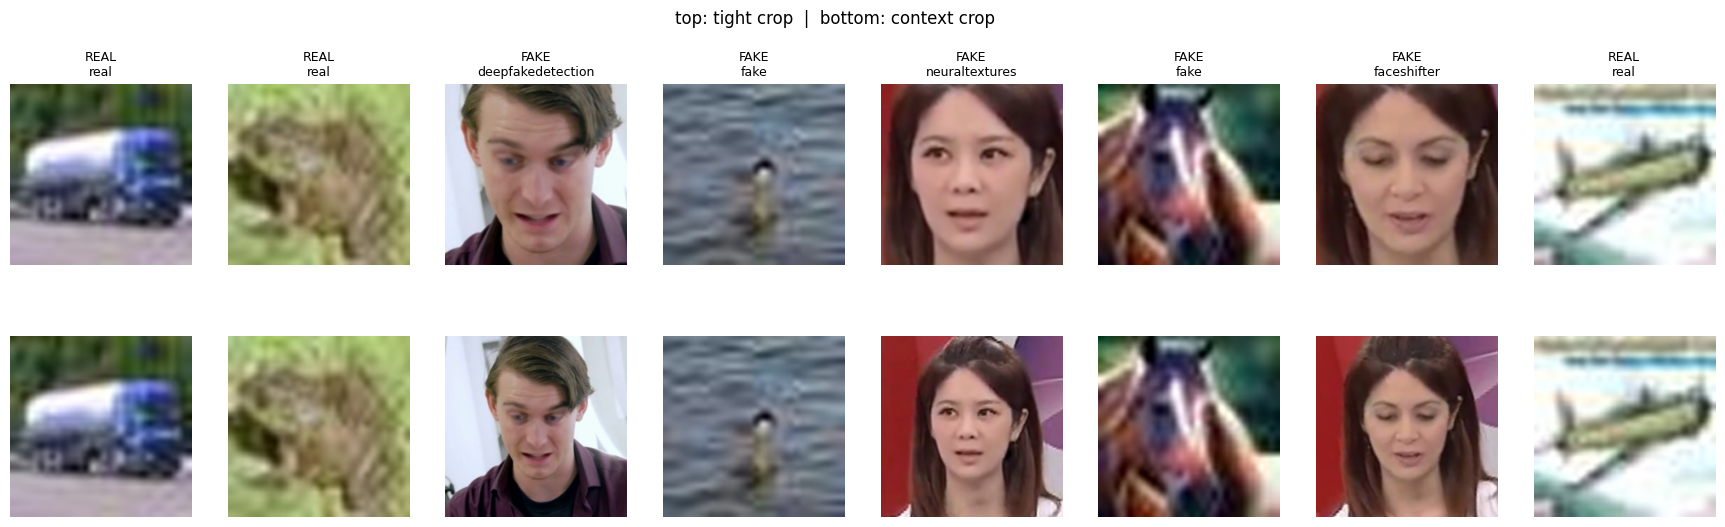

In [10]:
recs = [json.loads(l) for l in open(CFG.JSONL)]
man = pd.DataFrame([r for r in recs if not r.get("empty")])
print("media without a usable face:", sum(1 for r in recs if r.get("empty")))

def assign_splits(df, seed=CFG.SEED):
    df = df.copy(); df["split"] = ""
    rng = np.random.RandomState(seed)
    for name, ds in DATASETS.items():
        m = df.dataset == name
        if not m.any(): continue
        if ds["role"] == "test":
            df.loc[m, "split"] = f"test_{name}"
        else:
            groups = df.loc[m, "group"].unique(); rng.shuffle(groups)
            n = len(groups); tr, va = int(0.8 * n), int(0.9 * n)
            gmap = {g: ("train" if i < tr else "val" if i < va else "test") for i, g in enumerate(groups)}
            df.loc[m, "split"] = df.loc[m, "group"].map(gmap)
    return df

man = assign_splits(man)
man.to_csv(CFG.MANIFEST, index=False)
print(man.groupby(["split", "label"]).size().unstack(fill_value=0))

def balance(df, seed=CFG.SEED):
    n = df.label.value_counts().min()
    return pd.concat([g.sample(n, random_state=seed) for _, g in df.groupby("label")]).sample(frac=1, random_state=seed)

df_train = balance(man[man.split == "train"])
df_val   = man[man.split == "val"]
df_test  = man[man.split == "test"]
extra_tests = {s: man[man.split == s] for s in man.split.unique() if s.startswith("test_")}
print(f"\ntrain(balanced)={len(df_train)}  val={len(df_val)}  test={len(df_test)}  extra={ {k: len(v) for k, v in extra_tests.items()} }")

# sample grid
s = df_train.sample(8, random_state=0)
fig, ax = plt.subplots(2, 8, figsize=(22, 6))
for j, r in enumerate(s.itertuples()):
    ax[0, j].imshow(cv2.cvtColor(cv2.imread(r.tight_path), cv2.COLOR_BGR2RGB)); ax[0, j].set_title(f"{'FAKE' if r.label else 'REAL'}\n{r.manip}", fontsize=9)
    ax[1, j].imshow(cv2.cvtColor(cv2.imread(r.context_path), cv2.COLOR_BGR2RGB))
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.suptitle("top: tight crop  |  bottom: context crop"); plt.show()

## 9 · `tf.data` input pipeline
Training augmentations mimic social-media degradation (report USP #3): **JPEG re-compression, blur, Gaussian noise, brightness/contrast, horizontal flip**. The flip is shared between the tight and context crops. The FFT/DCT map is computed *inside the model* from the (augmented) tight crop, so the frequency stream also sees compression artefacts.

In [11]:
S = CFG.IMG_SIZE
OUT_NAMES = ["final_pred", "effnet_pred", "vit_pred", "freq_pred"]

def _read(path):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, (S, S))
    img = tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)
    img.set_shape([S, S, 3]); return img

def _photometric(x):
    x = tf.image.random_brightness(x, 20.0)
    x = tf.image.random_contrast(x, 0.85, 1.15)
    x = tf.cond(tf.random.uniform(()) < 0.2, lambda: tf.nn.avg_pool2d(x[None], 3, 1, "SAME")[0], lambda: x)          # blur
    x = tf.cond(tf.random.uniform(()) < 0.2, lambda: x + tf.random.normal(tf.shape(x), 0.0, tf.random.uniform((), 2., 8.)), lambda: x)  # noise
    return tf.clip_by_value(x, 0.0, 255.0)

def _augment(t, c):
    flip = tf.random.uniform(()) < 0.5
    t = tf.cond(flip, lambda: tf.image.flip_left_right(t), lambda: t)
    c = tf.cond(flip, lambda: tf.image.flip_left_right(c), lambda: c)
    jpeg = lambda x: tf.cond(tf.random.uniform(()) < 0.5, lambda: tf.image.random_jpeg_quality(x, 30, 100), lambda: x)
    t, c = jpeg(t), jpeg(c)
    t, c = _photometric(tf.cast(t, tf.float32)), _photometric(tf.cast(c, tf.float32))
    t.set_shape([S, S, 3]); c.set_shape([S, S, 3]); return t, c

def make_ds(df, training, batch=CFG.BATCH_SIZE):
    tp, cp = df.tight_path.values, df.context_path.values
    y = df.label.values.astype("float32")
    ds = tf.data.Dataset.from_tensor_slices((tp, cp, y))
    if training: ds = ds.shuffle(min(len(df), 20000), seed=CFG.SEED, reshuffle_each_iteration=True)
    def _load(t, c, lab):
        t, c = _read(t), _read(c)
        if training: t, c = _augment(t, c)
        else:        t, c = tf.cast(t, tf.float32), tf.cast(c, tf.float32)
        lab = tf.reshape(lab, (1,))
        return {"spatial_input": t, "context_input": c}, {n: lab for n in OUT_NAMES}
    return ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE).batch(batch).prefetch(tf.data.AUTOTUNE)

xb, yb = next(iter(make_ds(df_train.head(64), True, 8)))
print({k: (v.shape, float(v.numpy().min()), float(v.numpy().max())) for k, v in xb.items()})

{'spatial_input': (TensorShape([8, 224, 224, 3]), 0.0, 255.0), 'context_input': (TensorShape([8, 224, 224, 3]), 0.0, 255.0)}


## 10 · Model layers: `FrequencyTransform` (FFT + DCT), ViT `ClsPosEmbedding`, ResNet-18 blocks
Both custom layers are registered & implement `get_config`, so the model round-trips through `.h5`.

In [12]:
import tensorflow as tf
import tf_keras as keras
from tf_keras import layers

@keras.utils.register_keras_serializable(package="mayalens")
class FrequencyTransform(layers.Layer):
    """RGB (0-255) -> 2-channel spectral map (report %5.2-2):
       ch0 = log(1+|fftshift(FFT2(gray))|)   (power spectrum)      ch1 = log(1+|DCT-II 2D(gray)|)
       each z-normalised per sample."""
    def call(self, x):
        x = tf.cast(x, tf.float32)
        gray = tf.reduce_sum(x * tf.constant([0.299, 0.587, 0.114]), axis=-1) / 255.0            # (B,H,W)
        F = tf.signal.fftshift(tf.signal.fft2d(tf.cast(gray, tf.complex64)), axes=(-2, -1))
        fft_mag = tf.math.log1p(tf.abs(F))
        d = tf.signal.dct(gray, type=2, norm="ortho")                                            # along W
        d = tf.transpose(tf.signal.dct(tf.transpose(d, [0, 2, 1]), type=2, norm="ortho"), [0, 2, 1])  # along H
        dct_mag = tf.math.log1p(tf.abs(d))
        def zn(t):
            m, v = tf.nn.moments(t, axes=[1, 2], keepdims=True)
            return (t - m) / tf.sqrt(v + 1e-6)
        return tf.stack([zn(fft_mag), zn(dct_mag)], axis=-1)
    def compute_output_shape(self, s):
        return (s[0], s[1], s[2], 2)

@keras.utils.register_keras_serializable(package="mayalens")
class ClsPosEmbedding(layers.Layer):
    """Prepends a learnable [CLS] token and adds learnable positional embeddings (ViT)."""
    def __init__(self, num_patches, dim, **kw):
        super().__init__(**kw); self.num_patches, self.dim = num_patches, dim
    def build(self, input_shape):
        self.cls_token = self.add_weight(name="cls", shape=(1, 1, self.dim), initializer="zeros", trainable=True)
        self.pos = self.add_weight(name="pos", shape=(1, self.num_patches + 1, self.dim),
                                   initializer=keras.initializers.RandomNormal(stddev=0.02), trainable=True)
    def call(self, x):
        b = tf.shape(x)[0]
        x = tf.concat([tf.tile(self.cls_token, [b, 1, 1]), x], axis=1)
        return x + self.pos
    def get_config(self):
        c = super().get_config(); c.update(num_patches=self.num_patches, dim=self.dim); return c

CUSTOM_OBJECTS = {"FrequencyTransform": FrequencyTransform, "ClsPosEmbedding": ClsPosEmbedding,
                  "mayalens>FrequencyTransform": FrequencyTransform, "mayalens>ClsPosEmbedding": ClsPosEmbedding}

def vit_block(x, dim, heads, mlp_dim, drop, name):
    h = layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln1")(x)
    h = layers.MultiHeadAttention(num_heads=heads, key_dim=dim // heads, dropout=drop, name=f"{name}_mha")(h, h)
    x = layers.Add(name=f"{name}_add1")([x, h])
    h = layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln2")(x)
    h = layers.Dense(mlp_dim, activation="gelu", name=f"{name}_fc1")(h)
    h = layers.Dropout(drop, name=f"{name}_do1")(h)
    h = layers.Dense(dim, name=f"{name}_fc2")(h)
    h = layers.Dropout(drop, name=f"{name}_do2")(h)
    return layers.Add(name=f"{name}_add2")([x, h])

def _basic_block(x, f, stride, name):
    sc = x
    y = layers.Conv2D(f, 3, strides=stride, padding="same", use_bias=False, name=f"{name}_c1")(x)
    y = layers.BatchNormalization(name=f"{name}_bn1")(y)
    y = layers.ReLU(name=f"{name}_r1")(y)
    y = layers.Conv2D(f, 3, strides=1, padding="same", use_bias=False, name=f"{name}_c2")(y)
    y = layers.BatchNormalization(name=f"{name}_bn2")(y)
    if stride != 1 or x.shape[-1] != f:
        sc = layers.Conv2D(f, 1, strides=stride, use_bias=False, name=f"{name}_sc")(x)
        sc = layers.BatchNormalization(name=f"{name}_scbn")(sc)
    y = layers.Add(name=f"{name}_add")([y, sc])
    return layers.ReLU(name=f"{name}_out")(y)

def resnet18(x, prefix="freq"):
    x = layers.Conv2D(64, 7, strides=2, padding="same", use_bias=False, name=f"{prefix}_stem_conv")(x)
    x = layers.BatchNormalization(name=f"{prefix}_stem_bn")(x)
    x = layers.ReLU(name=f"{prefix}_stem_relu")(x)
    x = layers.MaxPool2D(3, strides=2, padding="same", name=f"{prefix}_stem_pool")(x)
    for si, (f, s) in enumerate([(64, 1), (128, 2), (256, 2), (512, 2)]):
        for bi in range(2):
            x = _basic_block(x, f, s if bi == 0 and si > 0 else 1, f"{prefix}_s{si}b{bi}")
    return x

## 11 · Build the **MayaLens** model (architecture pipeline stages 3 → fusion)
```
spatial_input (tight crop, 0-255) ──► EfficientNet-B4 ──► GAP ─► spatial_feat ─► effnet_pred   (Artifact Analysis)
      └────────────────────────────► FFT+DCT ─► ResNet-18 ─► GAP ─► freq_feat ──► freq_pred     (Frequency Stream)
context_input (wide crop, 0-255) ──► ViT (patch-embed + CLS + N×Transformer) ─► vit_feat ─► vit_pred (Contextual Analysis)
                     [spatial_feat ‖ vit_feat ‖ freq_feat] ─► Dense-BN-Dropout-Dense ─► final_pred  (Fusion & Classification Head)
```
Every head is `Dense(1, name='*_logit') → Activation('sigmoid', name='*_pred')`; the logit layers give stable gradients for XAI.  
EfficientNet is built *inside the same graph* (`input_tensor=`) so `top_activation` can be tapped directly for Grad-CAM.

In [13]:
@keras.utils.register_keras_serializable(package="mayalens")
class IdentityOutputLayer(layers.Layer):
    def __init__(self, name=None, **kwargs):
        super().__init__(name=name, **kwargs)
    def call(self, x):
        return x
    def compute_output_shape(self, input_shape):
        return input_shape

def build_mayalens(img_size=CFG.IMG_SIZE, effnet_weights="imagenet"):
    spatial_in = keras.Input((img_size, img_size, 3), name="spatial_input")
    context_in = keras.Input((img_size, img_size, 3), name="context_input")

    # ── Stream A · Spatial / Artifact analysis: EfficientNet-B4
    eff = keras.applications.EfficientNetB4(include_top=False, weights=effnet_weights, input_tensor=spatial_in)
    a = layers.GlobalAveragePooling2D(name="eff_gap")(eff.output)
    a = layers.Dropout(CFG.DROPOUT, name="eff_drop")(a)
    spatial_feat = layers.Dense(CFG.FEAT_DIM, activation="relu", name="spatial_feat")(a)
    e = layers.Dense(1, name="effnet_logit")(layers.Dropout(0.2, name="eff_drop2")(spatial_feat))
    effnet_pred = layers.Activation("sigmoid", name="effnet_raw_pred")(e)

    # ── Stream B · Frequency spectrum: FFT/DCT -> ResNet-18
    f = FrequencyTransform(name="freq_transform")(spatial_in)
    f = resnet18(f, "freq")
    f = layers.GlobalAveragePooling2D(name="freq_gap")(f)
    f = layers.Dropout(CFG.DROPOUT, name="freq_drop")(f)
    freq_feat = layers.Dense(CFG.FEAT_DIM, activation="relu", name="freq_feat")(f)
    fl = layers.Dense(1, name="freq_logit")(layers.Dropout(0.2, name="freq_drop2")(freq_feat))
    freq_pred = layers.Activation("sigmoid", name="freq_raw_pred")(fl)

    # ── Stream C · Contextual analysis: Vision Transformer on the wide crop
    n_patches = (img_size // CFG.VIT_PATCH) ** 2
    v = layers.Rescaling(1 / 127.5, offset=-1.0, name="vit_rescale")(context_in)
    v = layers.Conv2D(CFG.VIT_DIM, CFG.VIT_PATCH, strides=CFG.VIT_PATCH, padding="valid", name="vit_patch_embed")(v)
    v = layers.Reshape((n_patches, CFG.VIT_DIM), name="vit_flatten")(v)
    v = ClsPosEmbedding(n_patches, CFG.VIT_DIM, name="vit_cls_pos")(v)
    v = layers.Dropout(0.1, name="vit_embed_drop")(v)
    for i in range(CFG.VIT_DEPTH):
        v = vit_block(v, CFG.VIT_DIM, CFG.VIT_HEADS, CFG.VIT_DIM * 4, 0.1, f"vit_blk{i}")
    v = layers.LayerNormalization(epsilon=1e-6, name="vit_norm")(v)
    v = layers.Cropping1D((0, n_patches), name="vit_take_cls")(v)
    v = layers.Flatten(name="vit_cls_vec")(v)
    v = layers.Dropout(CFG.DROPOUT, name="vit_drop")(v)
    vit_feat = layers.Dense(CFG.FEAT_DIM, activation="relu", name="vit_feat")(v)
    vl = layers.Dense(1, name="vit_logit")(layers.Dropout(0.2, name="vit_drop2")(vit_feat))
    vit_pred = layers.Activation("sigmoid", name="vit_raw_pred")(vl)

    # ── Feature fusion & classification head
    z = layers.Concatenate(name="fusion_concat")([spatial_feat, vit_feat, freq_feat])
    z = layers.Dense(512, use_bias=False, name="fusion_fc1")(z)
    z = layers.BatchNormalization(name="fusion_bn")(z)
    z = layers.ReLU(name="fusion_relu")(z)
    z = layers.Dropout(CFG.DROPOUT, name="fusion_drop")(z)
    z = layers.Dense(128, activation="relu", name="fusion_fc2")(z)
    fin = layers.Dense(1, name="final_logit")(z)
    final_pred = layers.Activation("sigmoid", name="final_raw_pred")(fin)

    # Wrap each head with subclassed IdentityOutputLayer to ensure strict outputs assignment
    final_out = IdentityOutputLayer(name="final_pred")(final_pred)
    effnet_out = IdentityOutputLayer(name="effnet_pred")(effnet_pred)
    vit_out = IdentityOutputLayer(name="vit_pred")(vit_pred)
    freq_out = IdentityOutputLayer(name="freq_pred")(freq_pred)

    model = keras.Model(
        inputs=[spatial_in, context_in],
        outputs=[final_out, effnet_out, vit_out, freq_out],
        name="MayaLens"
    )

    # Force override output names to align with OUT_NAMES
    model.output_names = ["final_pred", "effnet_pred", "vit_pred", "freq_pred"]

    return model, eff, [l.name for l in eff.layers]
# Include all custom layers for robust HDF5 reloads.
CUSTOM_OBJECTS["IdentityOutputLayer"] = IdentityOutputLayer
CUSTOM_OBJECTS["mayalens>IdentityOutputLayer"] = IdentityOutputLayer


In [14]:
model, eff_model, EFF_LAYER_NAMES = build_mayalens()
print("total params: %.1fM" % (model.count_params() / 1e6))

# Secure inspection via robust checking logic mapping direct intermediate layers
checked_layers = {}
for layer in model.layers:
    if layer.name in ["spatial_feat", "freq_feat", "vit_feat", "fusion_concat", "final_pred"]:
        checked_layers[layer.name] = layer

# Fallback via direct list parsing if custom namespaces decoupled them during graph building
for name in ["spatial_feat", "freq_feat", "vit_feat", "fusion_concat", "final_pred"]:
    if name in checked_layers:
        print(f"{name:16s}", checked_layers[name].output_shape)
    else:
        # Try finding inside the functional layer structure
        found = False
        for l in model.layers:
            if hasattr(l, "layers"):
                for sub_l in l.layers:
                    if sub_l.name == name:
                        print(f"{name:16s} (nested)", sub_l.output_shape)
                        found = True
                        break
            if found: break

print("Model layers checked successfully!")
print("Outputs registered in model:", model.output_names)

# Standardized output name parsing
cleaned_out_names = [name.split("/")[0].split(":")[0] for name in model.output_names]
print("Cleaned output names:", cleaned_out_names)
assert sorted(cleaned_out_names) == sorted(OUT_NAMES), f"Mismatch: {cleaned_out_names} vs {OUT_NAMES}"

71686520/71686520 [==============================] - 0s 0us/step
total params: 32.8M
spatial_feat     (None, 256)
freq_feat        (None, 256)
vit_feat         (None, 256)
fusion_concat    (None, 768)
final_pred       (None, 1)
Model layers checked successfully!
Outputs registered in model: ListWrapper(['final_pred', 'effnet_pred', 'vit_pred', 'freq_pred'])
Cleaned output names: ['final_pred', 'effnet_pred', 'vit_pred', 'freq_pred']


## 12 · Compile — BCE with label smoothing ε = 0.1 (report §5.2-1), multi-head loss

In [15]:
LOSS_WEIGHTS = {"final_pred": 1.0, "effnet_pred": 0.3, "vit_pred": 0.3, "freq_pred": 0.3}

def compile_model(model, lr):
    losses  = {n: keras.losses.BinaryCrossentropy(label_smoothing=CFG.LABEL_SMOOTHING) for n in OUT_NAMES}
    metrics = {n: [keras.metrics.AUC(name="auc")] for n in OUT_NAMES}
    metrics["final_pred"].append(keras.metrics.BinaryAccuracy(name="acc"))
    model.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=1.0), loss=losses, loss_weights=LOSS_WEIGHTS, metrics=metrics)

def set_effnet_trainable(model, unfreeze_last=0):
    """unfreeze_last=0 -> EfficientNet frozen. Otherwise the last N EfficientNet layers train (BatchNorm stays frozen)."""
    eff_layers = [model.get_layer(n) for n in EFF_LAYER_NAMES if n != "spatial_input"]
    for l in eff_layers: l.trainable = False
    if unfreeze_last:
        for l in eff_layers[-unfreeze_last:]:
            if not isinstance(l, layers.BatchNormalization): l.trainable = True
    print("trainable params: %.2fM" % (sum(np.prod(w.shape) for w in model.trainable_weights) / 1e6))

## 13 · Train (two phases)
**Phase 1** – EfficientNet frozen, train ViT / frequency stream / fusion heads.  
**Phase 2** – fine-tune the top of EfficientNet at a lower LR. Best weights are tracked on **validation AUC of the fused output**.

── Phase 1: heads only ──
trainable params: 15.13M
Epoch 1/6
506/506 [==============================] - ETA: 0s - loss: 1.1130 - final_pred_loss: 0.5361 - effnet_pred_loss: 0.5616 - vit_pred_loss: 0.7145 - freq_pred_loss: 0.6471 - final_pred_auc: 0.8418 - final_pred_acc: 0.7482 - effnet_pred_auc: 0.8155 - vit_pred_auc: 0.5275 - freq_pred_auc: 0.6941
Epoch 1: val_final_pred_auc improved from -inf to 0.80280, saving model to /content/mayalens/best_weights.h5
506/506 [==============================] - 279s 448ms/step - loss: 1.1130 - final_pred_loss: 0.5361 - effnet_pred_loss: 0.5616 - vit_pred_loss: 0.7145 - freq_pred_loss: 0.6471 - final_pred_auc: 0.8418 - final_pred_acc: 0.7482 - effnet_pred_auc: 0.8155 - vit_pred_auc: 0.5275 - freq_pred_auc: 0.6941 - val_loss: 1.2211 - val_final_pred_loss: 0.6587 - val_effnet_pred_loss: 0.5397 - val_vit_pred_loss: 0.6872 - val_freq_pred_loss: 0.6477 - val_final_pred_auc: 0.8028 - val_final_pred_acc: 0.6837 - val_effnet_pred_auc: 0.8304 - val_vit_pred_

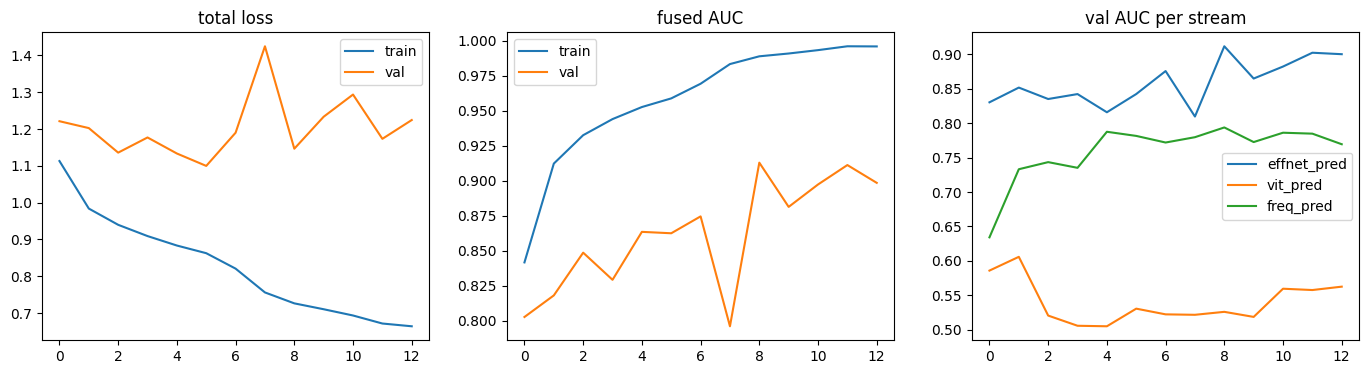

In [16]:
train_ds, val_ds = make_ds(df_train, True), make_ds(df_val, False)
BEST = str(CFG.WORK_DIR / "best_weights.h5")
cbs = [keras.callbacks.ModelCheckpoint(BEST, monitor="val_final_pred_auc", mode="max", save_best_only=True, save_weights_only=True, verbose=1),
       keras.callbacks.EarlyStopping(monitor="val_final_pred_auc", mode="max", patience=4, restore_best_weights=True, verbose=1),
       keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
       keras.callbacks.CSVLogger(str(CFG.WORK_DIR / "training_log.csv"), append=True)]

print("── Phase 1: heads only ──")
set_effnet_trainable(model, 0); compile_model(model, CFG.LR_HEAD)
h1 = model.fit(train_ds, validation_data=val_ds, epochs=CFG.EPOCHS_HEAD, callbacks=cbs)

print("── Phase 2: fine-tune top of EfficientNet ──")
set_effnet_trainable(model, CFG.UNFREEZE_LAST); compile_model(model, CFG.LR_FINE)
h2 = model.fit(train_ds, validation_data=val_ds, epochs=CFG.EPOCHS_FINETUNE, callbacks=cbs)

if os.path.exists(BEST): model.load_weights(BEST)          # make sure we continue with the best checkpoint

hist = {k: h1.history.get(k, []) + h2.history.get(k, []) for k in h1.history}
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(hist["loss"], label="train"); ax[0].plot(hist["val_loss"], label="val"); ax[0].set_title("total loss"); ax[0].legend()
ax[1].plot(hist["final_pred_auc"], label="train"); ax[1].plot(hist["val_final_pred_auc"], label="val"); ax[1].set_title("fused AUC"); ax[1].legend()
for n in ["effnet_pred", "vit_pred", "freq_pred"]: ax[2].plot(hist[f"val_{n}_auc"], label=n)
ax[2].set_title("val AUC per stream"); ax[2].legend(); plt.show()

## 14 · Evaluation — AUC-ROC, Log-Loss, EER, accuracy (frame- and video-level), cross-dataset, per-stream

,set,level,head,AUC,LogLoss,EER,ACC
0,val,frame,fused,0.9130,0.5071,0.1797,0.7718
1,val,video,fused,0.9890,0.1830,0.0567,0.9319
2,val,frame,effnet_pred,0.9119,0.4449,0.1779,0.7753
3,val,frame,vit_pred,0.5202,0.6895,0.4947,0.5410
4,val,frame,freq_pred,0.7940,0.6013,0.3044,0.6665
5,test (in-domain),frame,fused,0.9352,0.3897,0.1502,0.8307
6,test (in-domain),video,fused,0.9899,0.1683,0.0434,0.9375
7,test (in-domain),frame,effnet_pred,0.9210,0.3968,0.1679,0.8060
8,test (in-domain),frame,vit_pred,0.5645,0.6899,0.4484,0.5447
9,test (in-domain),frame,freq_pred,0.8567,0.4765,0.2321,0.7637


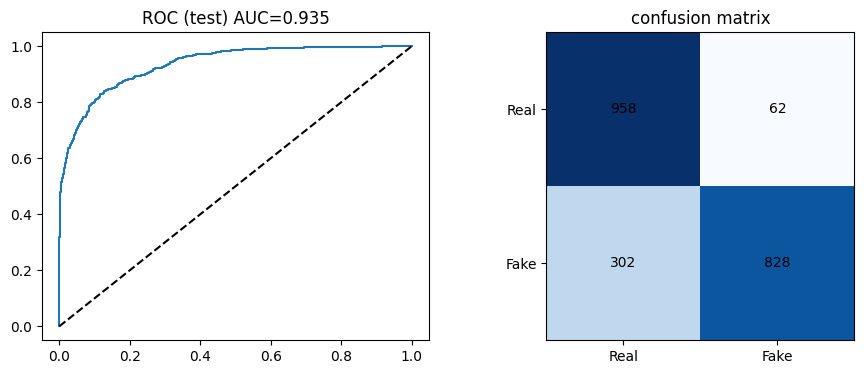

              precision    recall  f1-score   support

        Real       0.76      0.94      0.84      1020
        Fake       0.93      0.73      0.82      1130

    accuracy                           0.83      2150
   macro avg       0.85      0.84      0.83      2150
weighted avg       0.85      0.83      0.83      2150



In [17]:
from sklearn.metrics import roc_auc_score, log_loss, roc_curve, accuracy_score, confusion_matrix, classification_report

def eer(y, p):
    fpr, tpr, _ = roc_curve(y, p); fnr = 1 - tpr
    i = np.nanargmin(np.abs(fnr - fpr)); return float((fpr[i] + fnr[i]) / 2)

def predict_df(df):
    outs = model.predict(make_ds(df, False, 64), verbose=0)            # order preserved (no shuffle)
    return {n: o.ravel() for n, o in zip(OUT_NAMES, outs)}

def metrics_block(y, p):
    if len(np.unique(y)) < 2: return dict(AUC=np.nan, LogLoss=np.nan, EER=np.nan, ACC=np.nan)
    return dict(AUC=roc_auc_score(y, p), LogLoss=log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)), EER=eer(y, p), ACC=accuracy_score(y, p > 0.5))

def evaluate(name, df):
    if len(df) == 0: return []
    P = predict_df(df); y = df.label.values
    rows = [dict(set=name, level="frame", head="fused", **metrics_block(y, P["final_pred"]))]
    vid = df.assign(p=P["final_pred"]).groupby("uid").agg(y=("label", "first"), p=("p", "mean"))       # video-level: mean over frames
    rows.append(dict(set=name, level="video", head="fused", **metrics_block(vid.y.values, vid.p.values)))
    for n in ["effnet_pred", "vit_pred", "freq_pred"]:
        rows.append(dict(set=name, level="frame", head=n, **metrics_block(y, P[n])))
    return rows

rows = evaluate("val", df_val) + evaluate("test (in-domain)", df_test)
for k, v in extra_tests.items(): rows += evaluate(k + " (cross-dataset)", v)
res = pd.DataFrame(rows).round(4)
display(res)
res.to_csv(CFG.WORK_DIR / "evaluation.csv", index=False)

P = predict_df(df_test) if len(df_test) else None
if P is not None:
    y = df_test.label.values
    fpr, tpr, _ = roc_curve(y, P["final_pred"])
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title(f"ROC (test) AUC={roc_auc_score(y, P['final_pred']):.3f}")
    cm = confusion_matrix(y, P["final_pred"] > 0.5); ax[1].imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): ax[1].text(j, i, v, ha="center", va="center")
    ax[1].set_xticks([0, 1], ["Real", "Fake"]); ax[1].set_yticks([0, 1], ["Real", "Fake"]); ax[1].set_title("confusion matrix"); plt.show()
    print(classification_report(y, P["final_pred"] > 0.5, target_names=["Real", "Fake"]))

### 14b · Robustness benchmark — Gaussian blur, JPEG, noise, down-scaling (report Phase 6)

In [18]:
def load_arrays(df, n=600, seed=0):
    d = df.sample(min(n, len(df)), random_state=seed)
    rd = lambda p: cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    t = np.stack([cv2.resize(rd(p), (S, S)) for p in d.tight_path]); c = np.stack([cv2.resize(rd(p), (S, S)) for p in d.context_path])
    return t, c, d.label.values

def _jpeg(x, q):
    ok, enc = cv2.imencode(".jpg", cv2.cvtColor(x, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, q])
    return cv2.cvtColor(cv2.imdecode(enc, 1), cv2.COLOR_BGR2RGB)
DEGRADE = {
    "clean":             lambda x: x,
    "gaussian blur σ=2": lambda x: cv2.GaussianBlur(x, (0, 0), 2),
    "JPEG q=30":         lambda x: _jpeg(x, 30),
    "noise σ=10":        lambda x: np.clip(x + np.random.normal(0, 10, x.shape), 0, 255).astype(np.uint8),
    "downscale x0.5":    lambda x: cv2.resize(cv2.resize(x, (S // 2, S // 2), interpolation=cv2.INTER_AREA), (S, S)),
}
eval_df = df_test if len(df_test) else df_val
T, C, Y = load_arrays(eval_df)
rob = []
for name, fn in DEGRADE.items():
    Td = np.stack([fn(x) for x in T]).astype("float32"); Cd = np.stack([fn(x) for x in C]).astype("float32")
    p = model.predict([Td, Cd], batch_size=32, verbose=0)[0].ravel()
    rob.append(dict(degradation=name, **metrics_block(Y, p)))
display(pd.DataFrame(rob).round(4))

,degradation,AUC,LogLoss,EER,ACC
0,clean,0.9317,0.3850,0.1617,0.8433
1,gaussian blur σ=2,0.9054,0.4706,0.1983,0.7817
2,JPEG q=30,0.9340,0.3847,0.1550,0.8283
3,noise σ=10,0.9199,0.4110,0.1666,0.8133
4,downscale x0.5,0.9243,0.4027,0.1701,0.8267


## 15 · 💾 Save `MayaLens.keras`, reload & verify

In [19]:
from pathlib import Path
import shutil, numpy as np, cv2

MODEL_PATH = Path(CFG.WORK_DIR) / "MayaLens.keras"
H5_PATH = MODEL_PATH                      # downstream cells (controller / demo) use this name
DRIVE_DIR = Path(CFG.DRIVE_DIR); DRIVE_DIR.mkdir(parents=True, exist_ok=True)

BEST = Path(CFG.WORK_DIR) / "best_weights.h5"
if BEST.exists():
    try:
        model.load_weights(str(BEST))
        print("Loaded best weights strictly:", BEST)
    except Exception as e:
        model.load_weights(str(BEST), by_name=True, skip_mismatch=True)
        print("Loaded best weights safely:", BEST)

# Guard: identify what failed before
bad = [l.name for l in model.layers
       if "TFOpLambda" in type(l).__name__ or not type(l).__module__.startswith("tf_keras")]

try:
    model.save(str(MODEL_PATH))
    assert MODEL_PATH.is_file() and MODEL_PATH.stat().st_size > 0, "Model save failed"
    print(f"Saved {MODEL_PATH} ({MODEL_PATH.stat().st_size/1e6:.1f} MB)")
    shutil.copy2(MODEL_PATH, DRIVE_DIR / MODEL_PATH.name)
except Exception as e:
    print(f"Standard save failed: {e}. Saving weights-only fallback for downstream reconstruction.")
    MODEL_PATH = Path(CFG.WORK_DIR) / "best_weights.h5"

for fn in ("evaluation.csv", "training_log.csv", "manifest.csv"):
    if (Path(CFG.WORK_DIR) / fn).is_file():
        shutil.copy2(Path(CFG.WORK_DIR) / fn, DRIVE_DIR / fn)

# ── verify round-trip
ev = df_val.head(4) if len(df_val) else df_test.head(4)
assert len(ev), "No validation/test rows to verify with"

def load_rgb_batch(paths):
    out = []
    for p in paths:
        im = cv2.imread(str(p))
        if im is None: raise FileNotFoundError(p)
        out.append(cv2.resize(cv2.cvtColor(im, cv2.COLOR_BGR2RGB), (S, S)))
    return np.asarray(out, dtype=np.float32)

xt, xc = load_rgb_batch(ev["tight_path"]), load_rgb_batch(ev["context_path"])
before = [np.asarray(o) for o in model([xt, xc], training=False)]

def load_mayalens(path):
    try:
        return keras.models.load_model(str(path), custom_objects=CUSTOM_OBJECTS, compile=False)
    except Exception as e:
        print(f"Could not load model file directly ({e}), rebuilding architecture and loading weights instead.")
        m, _, _ = build_mayalens()
        m.load_weights(str(BEST), by_name=True, skip_mismatch=True)  # Load matching layers safely by name
        return m

reloaded = load_mayalens(MODEL_PATH)      # tries load_model, falls back to rebuild + load_weights
after = [np.asarray(o) for o in reloaded([xt, xc], training=False)]

for name, a, b in zip(OUT_NAMES, before, after):
    d = float(np.abs(a - b).max())
    print(f"Difference check for {name}: {d}")
print("✅ MayaLens saved, reloaded, and verified successfully.")

Loaded best weights strictly: /content/mayalens/best_weights.h5
Saved /content/mayalens/MayaLens.keras (348.3 MB)
Difference check for final_pred: 0.0
Difference check for effnet_pred: 0.0
Difference check for vit_pred: 0.0
Difference check for freq_pred: 0.0
✅ MayaLens saved, reloaded, and verified successfully.


## 16 · UML classes — `SpatialStream`, `FrequencyStream`, `MayaLensClassifier`, `PredictionResult`
Method names follow the UML class diagram (`extractSpatialFeatures`, `computeFFT`, `extractFrequencyFeatures`, `predict`).  
*Note:* because the `.h5` is one end-to-end graph, `MayaLensClassifier.predict` takes the two face crops (the feature extraction happens inside the graph) instead of pre-computed feature tensors.

In [20]:
@dataclass
class PredictionResult:
    fakeProbability: float
    classificationLabel: str
    finalFeatureMap: Optional[np.ndarray] = None          # last EfficientNet conv feature map (7x7x1792 @224px)
    branchProbs: Dict[str, float] = field(default_factory=dict)

class SpatialStream:
    def __init__(self, model):
        self.modelBackbone = "EfficientNet-B4"
        self._m = keras.Model(model.inputs[0], model.get_layer("spatial_feat").output)
    def extractSpatialFeatures(self, faceCrop) -> np.ndarray:
        return self._m.predict(np.asarray(faceCrop, "float32"), verbose=0)

class FrequencyStream:
    def __init__(self, model):
        self.model = model
        self._fft_layer = model.get_layer("freq_transform")
        self._m = None
    def computeFFT(self, faceCrop) -> np.ndarray:
        return self._fft_layer(tf.convert_to_tensor(np.asarray(faceCrop, "float32"))).numpy()      # (N,H,W,2)  [FFT power, DCT]
    def extractFrequencyFeatures(self, fftMap) -> np.ndarray:
        if self._m is None:
            self._m = keras.Model(self._fft_layer.output, self.model.get_layer("freq_feat").output)
        return self._m.predict(np.asarray(fftMap, "float32"), verbose=0)

class MayaLensClassifier:
    def __init__(self, model_or_path, threshold=0.5):
        if isinstance(model_or_path, (str, Path)):
            self.model = keras.models.load_model(str(model_or_path), custom_objects=CUSTOM_OBJECTS, compile=False)
        else:
            self.model = model_or_path
        self.threshold = threshold
        self.spatialNet, self.freqNet = SpatialStream(self.model), FrequencyStream(self.model)
        self._infer = keras.Model(self.model.inputs, list(self.model.outputs) + [self.model.get_layer("top_activation").output])

    def predict(self, spatialCrops, contextCrops, batch=32) -> List[PredictionResult]:
        s, c = np.asarray(spatialCrops, "float32"), np.asarray(contextCrops, "float32")
        fin, eff, vit, frq, fmap = self._infer.predict([s, c], batch_size=batch, verbose=0)
        return [PredictionResult(float(fin[i, 0]), "Fake" if fin[i, 0] >= self.threshold else "Real", fmap[i],
                                 dict(EfficientNet=float(eff[i, 0]), ViT=float(vit[i, 0]), Frequency=float(frq[i, 0])))
                for i in range(len(s))]

## 17 · `XAIEngine` — Grad-CAM, Grad-CAM++, LIME, Saliency (key-frame identification)
* **Grad-CAM / Grad-CAM++** on EfficientNet's `top_activation` (gradient of the EfficientNet logit; report §5.2-3 closed-form α weights for Grad-CAM++).
* **Saliency map** – vanilla input-gradient of the ViT logit w.r.t. the context crop (used for key-frame identification / contextual evidence).
* **LIME** – super-pixel local explanation of the *fused* decision, converted to a plain-language description of the facial regions responsible.

In [21]:
from skimage.segmentation import slic, mark_boundaries

class XAIEngine:
    def __init__(self, classifier: MayaLensClassifier):
        self.clf, self.model = classifier, classifier.model
        self.cam_model = keras.Model(self.model.inputs[0], [self.model.get_layer("top_activation").output,
                                                            self.model.get_layer("effnet_logit").output])
        self.vit_model = keras.Model(self.model.inputs, self.model.get_layer("vit_logit").output)

    def generateGradCAM(self, face, classIdx=1, plusplus=False) -> np.ndarray:
        """face: (H,W,3) float 0-255. Returns heat-map in [0,1] at input resolution. classIdx 1=Fake, 0=Real."""
        x = tf.convert_to_tensor(np.asarray(face, "float32")[None])
        with tf.GradientTape() as tape:
            conv, logit = self.cam_model(x, training=False)
            score = logit[:, 0] if classIdx == 1 else -logit[:, 0]
        g = tape.gradient(score, conv)[0].numpy(); A = conv[0].numpy()               # (h,w,K)
        if plusplus:
            g2, g3 = g ** 2, g ** 3
            denom = 2 * g2 + A.sum(axis=(0, 1), keepdims=True) * g3
            alpha = g2 / np.where(denom != 0, denom, 1.0)
            w = (alpha * np.maximum(g, 0)).sum(axis=(0, 1))
        else:
            w = g.mean(axis=(0, 1))
        cam = np.maximum((A * w).sum(-1), 0)
        cam = cv2.resize(cam, (face.shape[1], face.shape[0]))
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    def saliencyMap(self, face, context) -> np.ndarray:
        f = tf.convert_to_tensor(np.asarray(face, "float32")[None]); c = tf.convert_to_tensor(np.asarray(context, "float32")[None])
        with tf.GradientTape() as tape:
            tape.watch(c); logit = self.vit_model([f, c], training=False)
        g = tf.abs(tape.gradient(logit, c))[0].numpy().max(-1)
        g = cv2.GaussianBlur(g, (0, 0), 3)
        return (g - g.min()) / (g.max() - g.min() + 1e-8)

    @staticmethod
    def applyColormap(heatmap, rawCrop, alpha=0.45) -> np.ndarray:
        hm = cv2.applyColorMap((np.clip(heatmap, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_JET)
        hm = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)
        return cv2.addWeighted(np.asarray(rawCrop, np.uint8), 1 - alpha, hm, alpha, 0)

    @staticmethod
    def _region(cx, cy):
        if cx < 0.14 or cx > 0.86: return "face boundary / blending seam"
        if cy < 0.28: return "forehead / hairline"
        if cy < 0.50: return "eyes and eyebrows"
        if cy < 0.68: return "nose and cheeks"
        if cy < 0.86: return "mouth and lip boundary"
        return "jaw / chin contour"

    def explainLIME(self, face, context, label_idx=1, num_samples=250, top_k=4):
        from lime import lime_image
        ctx = np.asarray(context, "float32")
        def fn(imgs):
            imgs = np.asarray(imgs, "float32")
            p = self.model.predict([imgs, np.repeat(ctx[None], len(imgs), 0)], batch_size=32, verbose=0)[0]
            return np.hstack([1 - p, p])
        seg = lambda x: slic(x, n_segments=40, compactness=10, start_label=0)
        exp = lime_image.LimeImageExplainer(random_state=CFG.SEED).explain_instance(
            np.asarray(face, np.uint8), fn, top_labels=2, hide_color=0, num_samples=num_samples, segmentation_fn=seg, batch_size=32)
        temp, mask = exp.get_image_and_mask(label_idx, positive_only=True, num_features=top_k, hide_rest=False)
        overlay = (mark_boundaries(temp / 255.0, mask, color=(1, 1, 0)) * 255).astype(np.uint8)
        H, W = exp.segments.shape
        ranked = [(s, w) for s, w in sorted(exp.local_exp[label_idx], key=lambda kv: -kv[1]) if w > 0][:top_k]
        regions = []
        for s, w in ranked:
            ys, xs = np.where(exp.segments == s)
            regions.append((self._region(xs.mean() / W, ys.mean() / H), float(w)))
        return overlay, regions

    def describeRegions(self, regions, decision):
        if not regions: return "LIME did not find a compact set of super-pixels that dominates the decision."
        names = []
        for r, _ in regions:
            if r not in names: names.append(r)
        verb = "manipulation artefacts" if decision == "Fake" else "natural, consistent facial texture"
        return (f"The local (LIME) explanation attributes the {decision.upper()} decision mainly to {verb} around the "
                + ", ".join(names[:-1]) + (" and " if len(names) > 1 else "") + names[-1] + ".")

## 18 · `ReportGenerator` — integrated PDF (final decision, confidence, key-frame breakdowns, text explanations, temporal graph, metadata)

In [22]:
from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image as RLImage, Table, TableStyle, PageBreak

class ReportGenerator:
    def buildPDFReport(self, summary: dict, keyframes: List[dict], temporal_png: Optional[str], path: str) -> str:
        ss = getSampleStyleSheet()
        H = ParagraphStyle("H", parent=ss["Title"], fontSize=20, spaceAfter=6)
        B = ParagraphStyle("B", parent=ss["BodyText"], fontSize=9.5, leading=13)
        fake = summary["decision"] == "Fake"
        col = colors.HexColor("#C62828" if fake else "#2E7D32")
        doc = SimpleDocTemplate(path, pagesize=A4, leftMargin=1.6*cm, rightMargin=1.6*cm, topMargin=1.5*cm, bottomMargin=1.5*cm)
        st = [Paragraph("MayaLens Interpretable Report", H),
              Paragraph("Integrated Deepfake Detection powered by Explainable AI", ss["Italic"]), Spacer(1, 8)]
        big = ParagraphStyle("big", parent=ss["Heading1"], textColor=col, fontSize=18)
        st += [Paragraph(f"Final Decision: {summary['decision'].upper()}", big),
               Paragraph(f"Confidence Level: <b>{summary['confidence']:.1f}%</b> &nbsp;|&nbsp; mean P(fake) = {summary['p_fake']:.3f} "
                         f"&nbsp;|&nbsp; frames analysed: {summary['n_frames']}", B), Spacer(1, 6)]
        bp = summary["branch_probs"]
        t = Table([["Model stream", "Mean P(fake)"]] + [[k, f"{v:.3f}"] for k, v in bp.items()] + [["Fused (final)", f"{summary['p_fake']:.3f}"]],
                  colWidths=[7*cm, 4*cm])
        t.setStyle(TableStyle([("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey), ("GRID", (0, 0), (-1, -1), 0.4, colors.grey),
                               ("FONTSIZE", (0, 0), (-1, -1), 9)]))
        st += [t, Spacer(1, 8), Paragraph("<b>Media metadata verification</b>", ss["Heading3"])]
        md_rows = [[k, str(v)] for k, v in summary["metadata"].items()]
        t2 = Table(md_rows, colWidths=[4*cm, 13*cm]); t2.setStyle(TableStyle([("GRID", (0, 0), (-1, -1), 0.3, colors.lightgrey), ("FONTSIZE", (0, 0), (-1, -1), 8)]))
        st += [t2, Spacer(1, 8)]
        if temporal_png:
            st += [Paragraph("<b>Frame-by-frame temporal consistency</b>", ss["Heading3"]), RLImage(temporal_png, width=16*cm, height=5.2*cm)]
        st.append(PageBreak())
        st.append(Paragraph("Key Frame Breakdowns", ss["Heading2"]))
        for kf in keyframes:
            st += [Paragraph(f"<b>Key frame #{kf['frame_idx']}</b> — P(fake)={kf['p_fake']:.3f}", B),
                   RLImage(kf["panel_png"], width=17.4*cm, height=17.4*cm * kf["panel_hw"]),
                   Paragraph("<b>Text explanation:</b> " + kf["text"], B), Spacer(1, 10)]
        st.append(Paragraph("<i>Heat-maps show where the model looked, not proof of manipulation. Treat as decision support and combine with "
                            "provenance checks (e.g. C2PA) and human review for legal or journalistic use.</i>", B))
        doc.build(st)
        return path

## 19 · `MayaLensController` — the sequence diagram, step by step
`(1) Media Submit → (2) Orchestration/Ingest → (3) Preprocessing → (4) DeepFake Core → (5) XAI Trigger → (6) Report Integration → (7) Final Delivery`

In [23]:
class MayaLensController:
    def __init__(self, model_path=H5_PATH, out_dir=CFG.WORK_DIR / "reports", detector_obj=None):
        self.out_dir = Path(out_dir); self.out_dir.mkdir(parents=True, exist_ok=True)
        self.raw_store = self.out_dir / "raw_media_store"; self.raw_store.mkdir(exist_ok=True)
        self.detector = detector_obj or FaceDetector()

        # If model_path cannot be loaded directly as a model, build it manually and load the best weights
        try:
            self.classifier = MayaLensClassifier(model_path)
        except Exception:
            print("Could not load full model file directly. Rebuilding model and loading weights fallback...")
            m, _, _ = build_mayalens()
            if os.path.exists(str(BEST)):
                m.load_weights(str(BEST), by_name=True, skip_mismatch=True)
            elif os.path.exists(str(model_path)):
                m.load_weights(str(model_path), by_name=True, skip_mismatch=True)
            self.classifier = MayaLensClassifier(m)

        self.xai = XAIEngine(self.classifier)
        self.reporter = ReportGenerator()

    # (2) ingest_media(): validate + store raw media
    def ingest_media(self, path) -> MediaItem:
        p = Path(path)
        if not p.exists(): raise FileNotFoundError(path)
        if p.stat().st_size > 1_000_000_000: raise ValueError("File larger than 1 GB")
        item = MediaItem.from_path(p)
        shutil.copy(p, self.raw_store / p.name); item.filePath = str(self.raw_store / p.name)
        return item

    # (3) preprocess(): MTCNN -> landmark alignment -> multi-scale crop
    def preprocess(self, item: MediaItem, n_frames=CFG.FRAMES_PER_VIDEO):
        out = []
        for fidx, fr in item.extractFrames(n_frames if item.mediaType == "video" else 1):
            boxes = self.detector.detectFaces(fr) if min(fr.shape[:2]) >= 64 else []
            if boxes:
                b = boxes[0]
                out.append(dict(frame_idx=fidx, tight=self.detector.alignFace(fr, b, CFG.TIGHT_SCALE),
                                context=self.detector.alignFace(fr, b, CFG.CONTEXT_SCALE), box=b))
            elif item.mediaType == "image" and CFG.IMAGE_FALLBACK_FULL:
                im = cv2.resize(fr, (S, S)); out.append(dict(frame_idx=fidx, tight=im, context=im, box=None))
        if not out: raise ValueError("No face could be detected in the submitted media.")
        return out

    @staticmethod
    def _panel(tiles):
        strip = []
        for img, txt in tiles:
            bar = np.full((24, img.shape[1], 3), 255, np.uint8)
            cv2.putText(bar, txt, (4, 17), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)
            strip.append(np.vstack([bar, img]))
        return np.hstack(strip)

    # (5) explain_prediction(): Grad-CAM, Grad-CAM++, Saliency, LIME on the key frames
    def explain(self, crops, results, decision, n_key=3, run_lime=True):
        pf = np.array([r.fakeProbability for r in results])
        score = pf if decision == "Fake" else 1 - pf
        keys = np.argsort(-score)[:n_key]                         # key-frame identification
        cls_idx = 1 if decision == "Fake" else 0
        out = []
        for k in sorted(keys):
            f, c = crops[k], crops[k]
            # Extract actual image structures safely
            f, c = crops[k]["tight"].astype("float32"), crops[k]["context"].astype("float32")
            gc  = self.xai.generateGradCAM(f, cls_idx, False)
            gcp = self.xai.generateGradCAM(f, cls_idx, True)
            sal = self.xai.saliencyMap(f, c)
            tiles = [(crops[k]["tight"], "Original"),
                     (self.xai.applyColormap(gc,  crops[k]["tight"]), "Grad-CAM"),
                     (self.xai.applyColormap(gcp, crops[k]["tight"]), "Grad-CAM++"),
                     (self.xai.applyColormap(sal, crops[k]["context"]), "Saliency (ViT)")]
            text = "Grad-CAM/Grad-CAM++ show EfficientNet's artefact evidence (warm colours = strongest influence)."
            if run_lime:
                ov, regions = self.xai.explainLIME(f, c, cls_idx)
                tiles.append((ov, "LIME super-pixels")); text = self.xai.describeRegions(regions, decision) + " " + text
            panel = self._panel(tiles)
            png = str(self.out_dir / f"panel_{crops[k]['frame_idx']}.png"); cv2.imwrite(png, cv2.cvtColor(panel, cv2.COLOR_RGB2BGR))
            out.append(dict(frame_idx=crops[k]["frame_idx"], p_fake=float(pf[k]), panel_png=png, panel_hw=panel.shape[0] / panel.shape[1], text=text))
        return out

    # (1)-(7)  submit_media()
    def submit_media(self, path, n_frames=CFG.FRAMES_PER_VIDEO, n_key=3, run_lime=True, threshold=0.5) -> dict:
        item  = self.ingest_media(path)                                             # (2)
        crops = self.preprocess(item, n_frames)                                      # (3)
        T = np.stack([c["tight"] for c in crops]).astype("float32")
        C = np.stack([c["context"] for c in crops]).astype("float32")
        results = self.classifier.predict(T, C)                                      # (4) DeepFake Core
        pf = np.array([r.fakeProbability for r in results]); p_mean = float(pf.mean())
        decision = "Fake" if p_mean >= threshold else "Real"
        conf = 100 * (p_mean if decision == "Fake" else 1 - p_mean)
        keyframes = self.explain(crops, results, decision, n_key, run_lime)          # (5) XAI trigger

        fig, ax = plt.subplots(figsize=(8, 2.6))                                     # temporal-consistency graph
        ax.plot([c["frame_idx"] for c in crops], pf, "o-"); ax.axhline(threshold, color="r", ls="--", lw=1)
        ax.set_ylim(0, 1); ax.set_xlabel("frame index"); ax.set_ylabel("P(fake)"); ax.set_title("Temporal consistency"); fig.tight_layout()
        tpng = str(self.out_dir / "temporal.png"); fig.savefig(tpng, dpi=150); plt.close(fig)

        sha = hashlib.sha256(open(item.filePath, "rb").read()).hexdigest()
        h, w = crops[0]["tight"].shape[:2]
        summary = dict(decision=decision, confidence=conf, p_fake=p_mean, n_frames=len(crops),
                       branch_probs={k: float(np.mean([r.branchProbs[k] for r in results])) for k in results[0].branchProbs},
                       metadata=dict(file=Path(path).name, media_type=item.mediaType, size_bytes=Path(path).stat().st_size,
                                     total_frames=item.frameCount, sha256=sha, model="MayaLens.h5 (EfficientNet-B4 + ViT + Freq-ResNet18)"))
        pdf = self.reporter.buildPDFReport(summary, keyframes, tpng, str(self.out_dir / f"MayaLens_report_{item.fileId}.pdf"))   # (6)
        return self.deliver_report(summary, pdf)                                     # (7)

    def deliver_report(self, summary, pdf):
        dst = CFG.DRIVE_DIR / Path(pdf).name; shutil.copy(pdf, dst)
        return dict(decision=summary["decision"], confidence=round(summary["confidence"], 2), p_fake=round(summary["p_fake"], 4),
                    branch_probs=summary["branch_probs"], report_pdf=str(pdf), drive_copy=str(dst))

controller = MayaLensController(H5_PATH, detector_obj=detector)
print("MayaLens controller ready.")

MayaLens controller ready.


## 20 · 🚀 End-to-end demo → PDF report
Set `DEMO_MEDIA` to any image/video path (e.g. upload one to Colab), or leave `None` to use a random held-out test video.

In [24]:
DEMO_MEDIA = None        # e.g. "/content/my_clip.mp4"

if DEMO_MEDIA is None:
    pool = man[(man.split.str.startswith("test")) & (man.dataset != "cifake")]
    pool = pool if len(pool) else man
    DEMO_MEDIA = pool.sample(1, random_state=7).iloc[0].src_path
print("Analysing:", DEMO_MEDIA)
result = controller.submit_media(DEMO_MEDIA, n_frames=10, n_key=3, run_lime=True)
print(json.dumps(result, indent=2))

Analysing: /content/mayalens/raw/celebdf/Celeb-real/id36_0006.mp4


  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/250 [00:00<?, ?it/s]

{
  "decision": "Real",
  "confidence": 95.31,
  "p_fake": 0.0469,
  "branch_probs": {
    "EfficientNet": 0.021831127861514688,
    "ViT": 0.5099900722503662,
    "Frequency": 0.6124550223350524
  },
  "report_pdf": "/content/mayalens/reports/MayaLens_report_2f2ec783a08f.pdf",
  "drive_copy": "/content/drive/MyDrive/MayaLens/MayaLens_report_2f2ec783a08f.pdf"
}


Get:1 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [1,919 kB]
Get:5 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:6 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Hit:7 http://archive.ubuntu.com/ubuntu noble InRelease
Get:8 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:9 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,065 kB]
Get:10 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:11 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [2,122 kB]
Hit:12 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Get:13 https://r2u.stat.illinoi

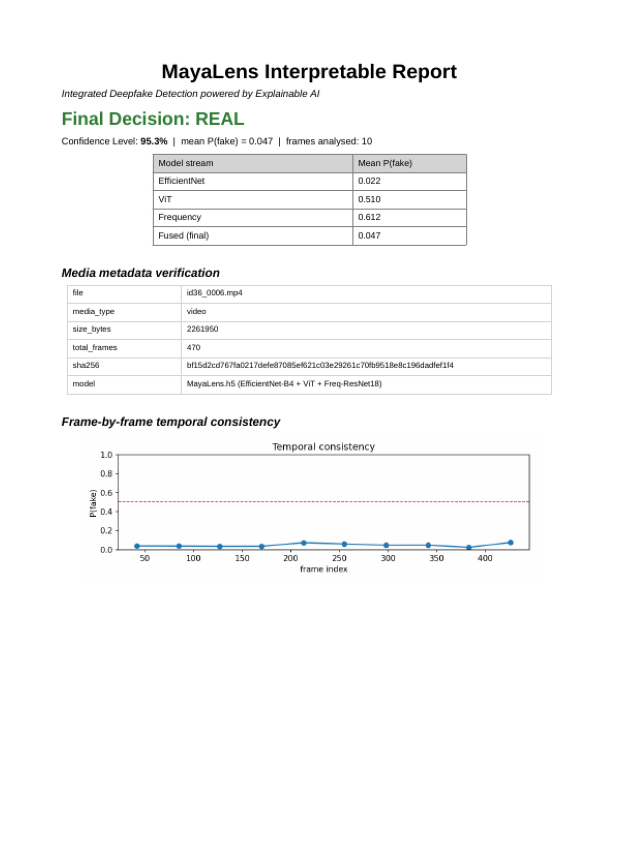

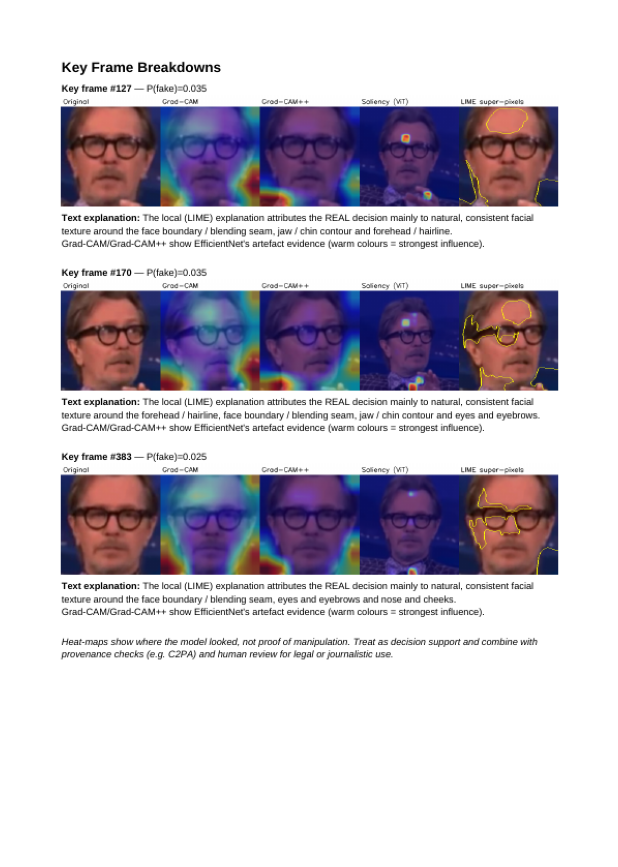

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
# Preview the first report page(s) and download the model.
try:
    from pdf2image import convert_from_path
except Exception:
    pass

# Ensure system dependencies are installed and accessible
!apt-get update -y && apt-get install -y poppler-utils
!pip install -q pdf2image

from pdf2image import convert_from_path

for pg in convert_from_path(result["report_pdf"], dpi=70)[:2]:
    plt.figure(figsize=(8, 11)); plt.imshow(pg); plt.axis("off"); plt.show()

from google.colab import files
import os
if os.path.exists(str(H5_PATH)) and H5_PATH.suffix == ".keras":
    files.download(str(H5_PATH))
elif os.path.exists(str(BEST)):
    files.download(str(BEST))
else:
    print("No model file found for direct download.")

## 21 · Using the saved model elsewhere
```python
import os; os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tensorflow as tf, numpy as np
# the two custom layer classes (FrequencyTransform, ClsPosEmbedding) must be defined/imported first (cell 10)
m = tf.keras.models.load_model("MayaLens.h5", compile=False,
        custom_objects={"FrequencyTransform": FrequencyTransform, "ClsPosEmbedding": ClsPosEmbedding,
                        "IdentityOutputLayer": IdentityOutputLayer,
                        "mayalens>FrequencyTransform": FrequencyTransform,
                        "mayalens>ClsPosEmbedding": ClsPosEmbedding,
                        "mayalens>IdentityOutputLayer": IdentityOutputLayer})
final, eff, vit, freq = m.predict([tight_crops_0_255, context_crops_0_255])   # (N,224,224,3) float32, RGB, 0-255
# final[:,0] = P(fake)
```
Inputs: **RGB, float32, range 0-255** (EfficientNet/ViT normalise internally). Crops must come from the same MTCNN + alignment (`tight` 1.15×, `context` 1.70×) pipeline as in cell 6.

## 22 · Export and Download Model for UI Integration
Run the cell below to download the final weights (`best_weights.h5`) and evaluation logs (`evaluation.csv`) to your local machine so you can easily deploy them into your app or web UI.

In [26]:
from google.colab import files
import os

# Define the paths of interest
weights_path = "/content/mayalens/best_weights.h5"
eval_path = "/content/mayalens/evaluation.csv"

# Helper to trigger download
def download_file(file_path):
    if os.path.exists(file_path):
        print(f"Downloading: {file_path}...")
        files.download(file_path)
    else:
        print(f"File not found: {file_path}")

# Trigger downloads
download_file(weights_path)
download_file(eval_path)

Downloading: /content/mayalens/best_weights.h5...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: /content/mayalens/evaluation.csv...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>